# HR Employee Attrition — Exploratory Data Analysis

**Question:** Who leaves the company, when, and why? Which factors matter most, and which don't matter at all?

**Data:** IBM HR Analytics Employee Attrition & Performance, 1,470 employees, 35 columns.
> ⚠️ **This is a fictional dataset created by IBM data scientists** to demonstrate HR analytics. The patterns are realistic but not from a real company. This project demonstrates the EDA method: the same steps apply to real HR data.

**Approach:** data quality → overall rate → who leaves → when → pay → statistical ranking of drivers → combinations of risk factors → what *doesn't* matter.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=0.95)
LEFT, STAYED, ACCENT = "#D85A30", "#B4B2A9", "#185FA5"
IMG = "../images/"
pd.set_option("display.float_format", "{:,.3f}".format)

df = pd.read_csv("../data/emp_attrition.csv", encoding="utf-8-sig")
print(df.shape)   # expect (1470, 35)

(1470, 35)


## 2. Data quality

In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate employee IDs:", df["EmployeeNumber"].duplicated().sum())

constant = [c for c in df.columns if df[c].nunique() == 1]
print("Columns with a single value:", constant)

Missing values: 0
Duplicate rows: 0
Duplicate employee IDs: 0
Columns with a single value: ['EmployeeCount', 'Over18', 'StandardHours']


Clean on the usual checks: no missing values, no duplicates. Three columns hold the same value for everyone (`EmployeeCount`, `Over18`, `StandardHours`), so they carry no information.

**A less obvious check:** the dataset has `DailyRate`, `HourlyRate` and `MonthlyRate`. If these were pay, they should move with `MonthlyIncome`.

In [3]:
df[["DailyRate", "HourlyRate", "MonthlyRate", "MonthlyIncome"]].corr().round(3)

,DailyRate,HourlyRate,MonthlyRate,MonthlyIncome
DailyRate,1.000,0.023,-0.032,0.008
HourlyRate,0.023,1.000,-0.015,-0.016
MonthlyRate,-0.032,-0.015,1.000,0.035
MonthlyIncome,0.008,-0.016,0.035,1.000


All correlations are close to 0. These "rate" columns are **not related to salary**, and they're undocumented, so they're dropped as noise. `MonthlyIncome` is the pay measure used from here on. Questioning a column before using it is part of EDA.

In [4]:
drop = constant + ["EmployeeNumber", "DailyRate", "HourlyRate", "MonthlyRate"]
df = df.drop(columns=drop)
df["Left"] = (df["Attrition"] == "Yes").astype(int)
print(df.shape)   # expect (1470, 29)

(1470, 29)


## 3. Decode codes and create bands
Survey-style columns are stored as numbers (1–4). Turning them into labels makes every chart readable.

In [5]:
labels = {
    "Education": {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"},
    "EnvironmentSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobSatisfaction":         {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "RelationshipSatisfaction":{1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobInvolvement":          {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "WorkLifeBalance":         {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
    "PerformanceRating":       {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"},
}
for col, mapping in labels.items():
    df[col] = df[col].map(mapping)

df["AgeBand"]    = pd.cut(df["Age"], [17, 25, 30, 35, 45, 60], labels=["18-25", "26-30", "31-35", "36-45", "46-60"])
df["TenureBand"] = pd.cut(df["YearsAtCompany"], [-1, 0, 1, 2, 5, 10, 40], labels=["<1 yr", "1 yr", "2 yrs", "3-5 yrs", "6-10 yrs", "11+ yrs"])
df["IncomeQuartile"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
df["BusinessTravel"] = df["BusinessTravel"].str.replace("_", " ").str.replace("Travel ", "Travels ")
df[["AgeBand", "TenureBand", "IncomeQuartile"]].head()

,AgeBand,TenureBand,IncomeQuartile
0,36-45,6-10 yrs,Q3
1,46-60,6-10 yrs,Q3
2,36-45,<1 yr,Q1 (lowest)
3,31-35,6-10 yrs,Q1 (lowest)
4,26-30,2 yrs,Q2


## 4. Overall attrition rate
Every rate in this notebook comes with a **95% confidence interval** (Wilson method). With small groups (e.g. 52 HR staff) a rate can look extreme by chance, so the interval shows how sure we can be.

In [6]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def rate_table(col):
    g = df.groupby(col, observed=True)["Left"].agg(employees="count", leavers="sum")
    g["rate"] = g["leavers"] / g["employees"]
    ci = g.apply(lambda r: wilson_ci(r["leavers"], r["employees"]), axis=1)
    g["ci_low"], g["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
    return g

OVERALL = df["Left"].mean()
lo, hi = wilson_ci(df["Left"].sum(), len(df))
print(f"{df['Left'].sum()} of {len(df)} employees left = {OVERALL:.1%} (95% CI {lo:.1%} to {hi:.1%})")

237 of 1470 employees left = 16.1% (95% CI 14.3% to 18.1%)


In [7]:
def plot_rate(col, ax, title=None, sort=True):
    t = rate_table(col)
    if sort:
        t = t.sort_values("rate")
    y = np.arange(len(t))
    colors = [LEFT if r > OVERALL else STAYED for r in t["rate"]]
    ax.barh(y, t["rate"], color=colors)
    ax.errorbar(t["rate"], y, xerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]],
                fmt="none", ecolor="#444441", elinewidth=1, capsize=2)
    ax.axvline(OVERALL, ls="--", color=ACCENT, lw=1)
    ax.set_yticks(y, [f"{i}  (n={n})" for i, n in zip(t.index, t["employees"])])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(title or col, loc="left", fontsize=11)
    ax.set_xlabel("")
    return t

## 5. Who leaves?
Bars above the company average (dashed line, 16.1%) are orange. Error bars are 95% confidence intervals.

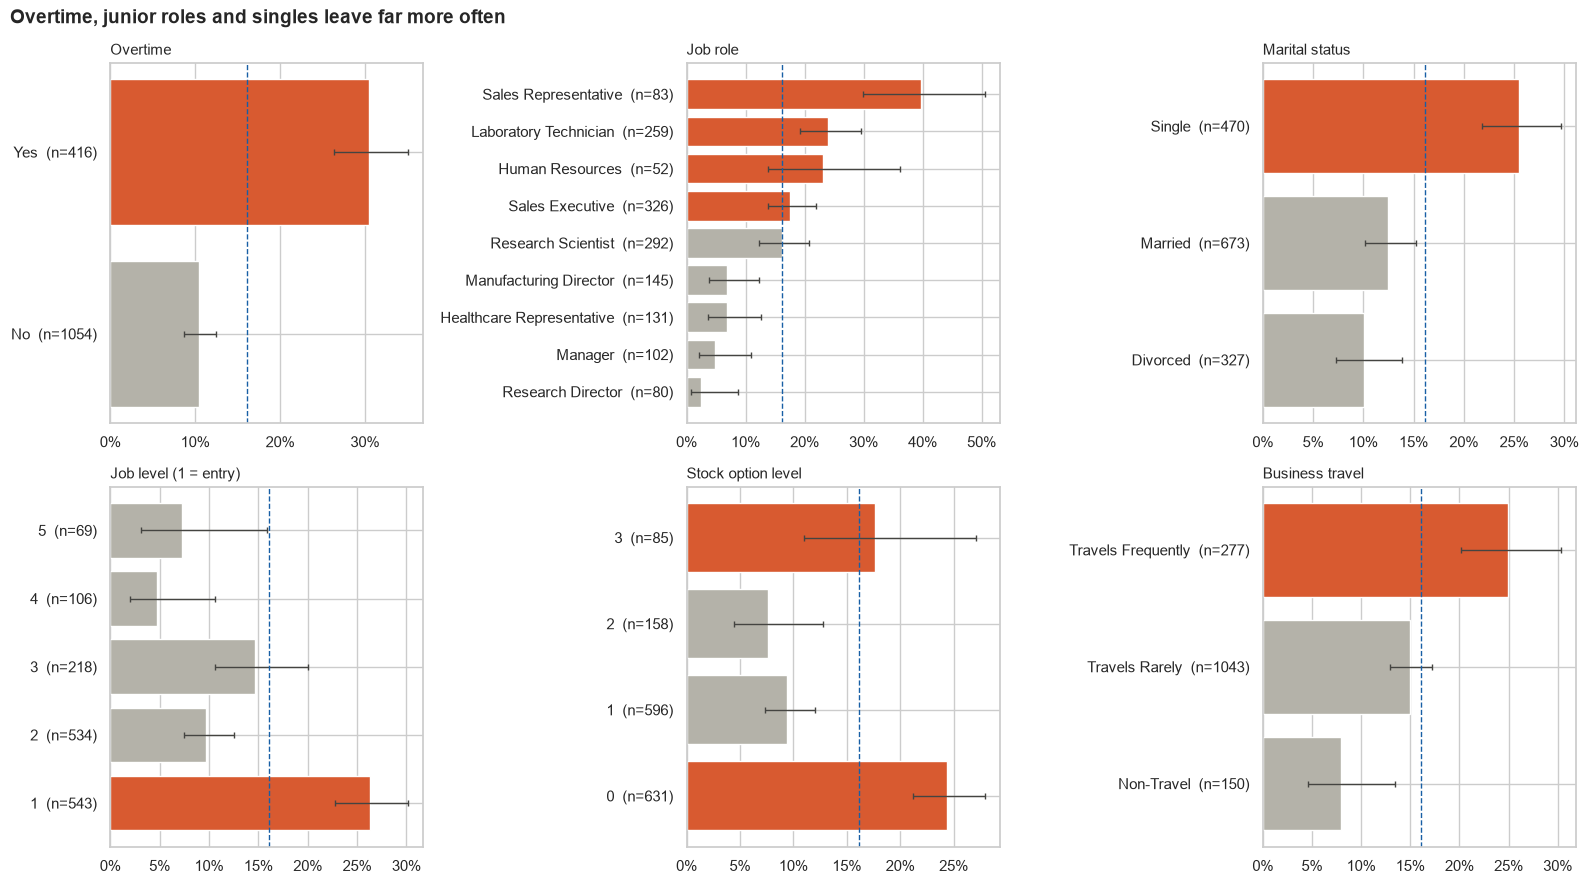

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_rate("OverTime", axes[0, 0], "Overtime")
plot_rate("JobRole", axes[0, 1], "Job role")
plot_rate("MaritalStatus", axes[0, 2], "Marital status")
plot_rate("JobLevel", axes[1, 0], "Job level (1 = entry)", sort=False)
plot_rate("StockOptionLevel", axes[1, 1], "Stock option level", sort=False)
plot_rate("BusinessTravel", axes[1, 2], "Business travel")
fig.suptitle("Overtime, junior roles and singles leave far more often", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "01_who_leaves.png", dpi=120, bbox_inches="tight"); plt.show()

In [9]:
rate_table("JobRole").sort_values("rate", ascending=False)

,employees,leavers,rate,ci_low,ci_high
JobRole,,,,,
Sales Representative,83,33,0.398,0.299,0.505
Laboratory Technician,259,62,0.239,0.191,0.295
Human Resources,52,12,0.231,0.137,0.361
Sales Executive,326,57,0.175,0.137,0.220
Research Scientist,292,47,0.161,0.123,0.207
Manufacturing Director,145,10,0.069,0.038,0.122
Healthcare Representative,131,9,0.069,0.037,0.125
Manager,102,5,0.049,0.021,0.110
Research Director,80,2,0.025,0.007,0.087


**Reading it:** Sales Representatives leave at 39.8%, about 2.5× the average, while Research Directors leave at 2.5%. Employees doing overtime leave at 30.5% vs 10.4%. Entry-level (Job Level 1) and employees with no stock options stand out too.

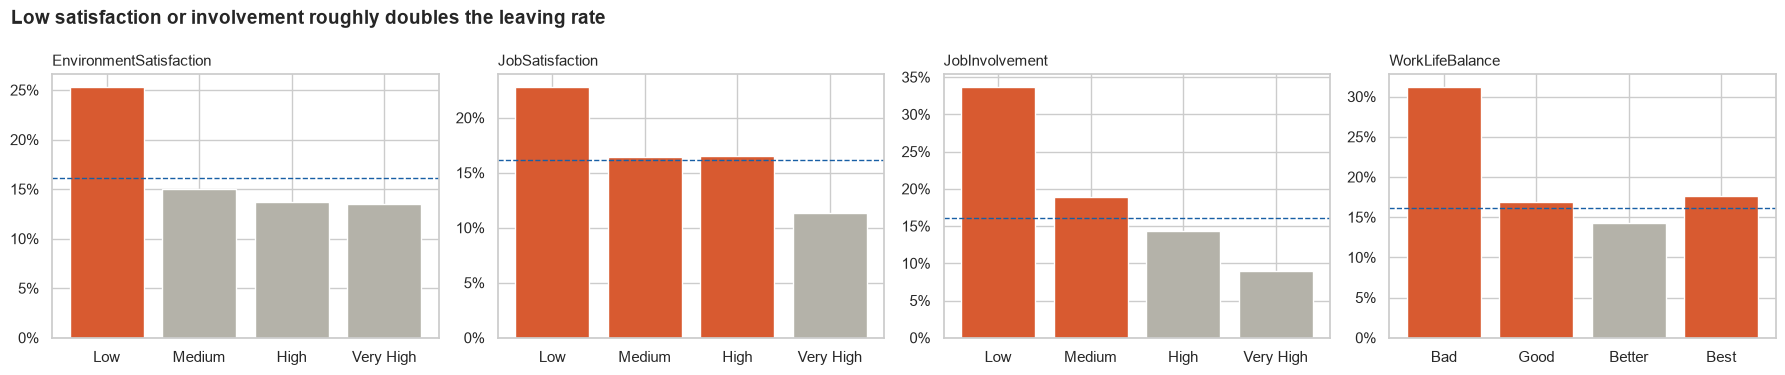

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
order = ["Low", "Medium", "High", "Very High"]
for ax, col in zip(axes, ["EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement"]):
    t = rate_table(col).reindex(order)
    ax.bar(t.index, t["rate"], color=[LEFT if r > OVERALL else STAYED for r in t["rate"]])
    ax.axhline(OVERALL, ls="--", color=ACCENT, lw=1); ax.set_title(col, loc="left", fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
t = rate_table("WorkLifeBalance").reindex(["Bad", "Good", "Better", "Best"])
axes[3].bar(t.index, t["rate"], color=[LEFT if r > OVERALL else STAYED for r in t["rate"]])
axes[3].axhline(OVERALL, ls="--", color=ACCENT, lw=1); axes[3].set_title("WorkLifeBalance", loc="left", fontsize=11)
axes[3].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Low satisfaction or involvement roughly doubles the leaving rate", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "02_satisfaction.png", dpi=120, bbox_inches="tight"); plt.show()

## 6. When do they leave?

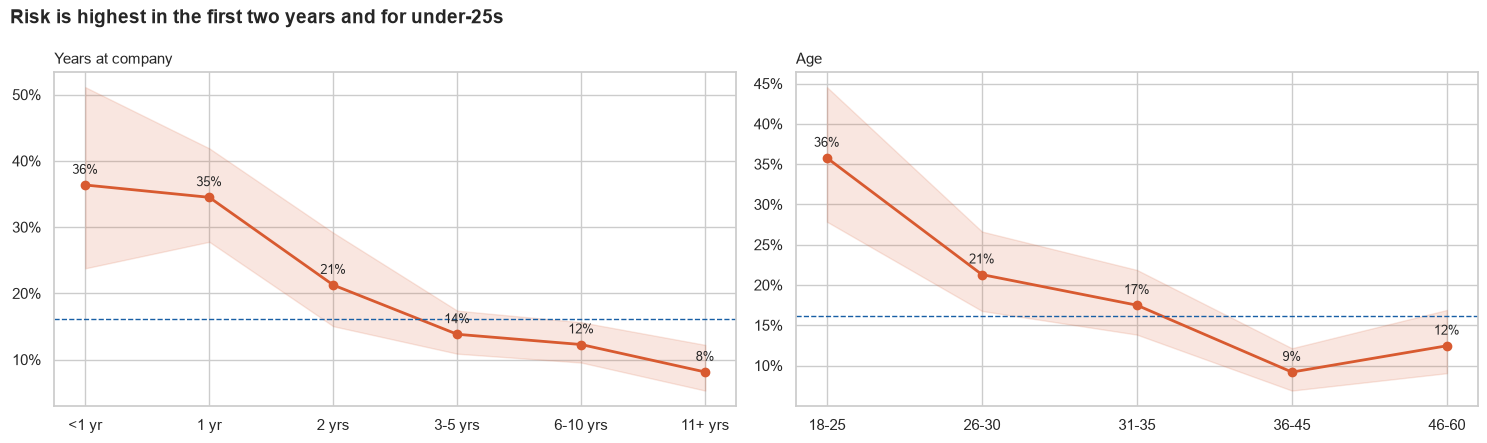

43% of all leavers left within their first 2 years


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, title in [(axes[0], "TenureBand", "Years at company"), (axes[1], "AgeBand", "Age")]:
    t = rate_table(col)
    x = np.arange(len(t))
    ax.plot(x, t["rate"], "o-", color=LEFT, lw=2)
    ax.fill_between(x, t["ci_low"], t["ci_high"], color=LEFT, alpha=0.15)
    ax.axhline(OVERALL, ls="--", color=ACCENT, lw=1)
    ax.set_xticks(x, t.index); ax.set_title(title, loc="left", fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for xi, r, n in zip(x, t["rate"], t["employees"]):
        ax.annotate(f"{r:.0%}", (xi, r), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
fig.suptitle("Risk is highest in the first two years and for under-25s", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "03_when_they_leave.png", dpi=120, bbox_inches="tight"); plt.show()

early = (df.loc[df["Left"] == 1, "YearsAtCompany"] <= 2).mean()
print(f"{early:.0%} of all leavers left within their first 2 years")

## 7. Does pay matter?

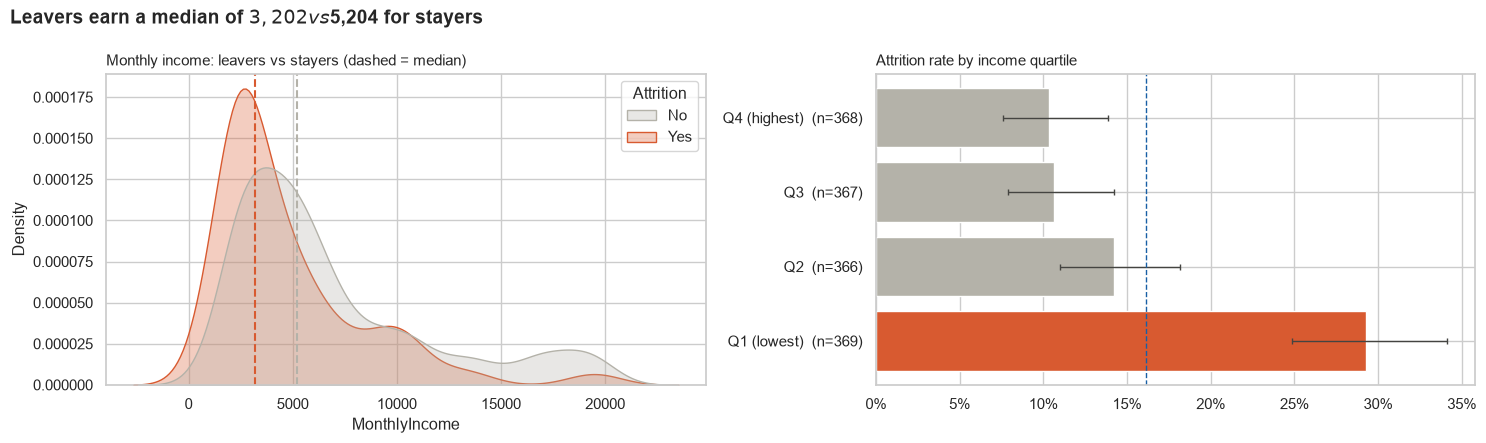

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.kdeplot(data=df, x="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"], palette=[STAYED, LEFT],
            common_norm=False, fill=True, alpha=0.3, ax=axes[0])
for val, c in [("No", STAYED), ("Yes", LEFT)]:
    axes[0].axvline(df.loc[df["Attrition"] == val, "MonthlyIncome"].median(), color=c, ls="--")
axes[0].set_title("Monthly income: leavers vs stayers (dashed = median)", loc="left", fontsize=11)
plot_rate("IncomeQuartile", axes[1], "Attrition rate by income quartile", sort=False)
fig.suptitle("Leavers earn a median of $3,202 vs $5,204 for stayers", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "04_pay.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Which factors matter most? A statistical ranking
Charts can mislead, so every factor is tested:
- **Categorical** factors: chi-square test, strength measured by **Cramér's V** (0 = no link, 1 = perfect).
- **Numeric** factors: Mann-Whitney U test (no normality assumption), strength measured by **rank-biserial correlation** (−1 to 1; negative = leavers have lower values).

The p-value says whether a difference is likely real; the effect size says whether it's big enough to care about.

In [13]:
cat_cols = ["OverTime", "JobRole", "JobLevel", "StockOptionLevel", "MaritalStatus", "JobInvolvement",
            "BusinessTravel", "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance", "EducationField",
            "Department", "RelationshipSatisfaction", "Education", "Gender", "PerformanceRating"]
rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df["Left"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"factor": c, "type": "categorical", "test": "chi-square", "p_value": p, "effect": v})

num_cols = ["TotalWorkingYears", "MonthlyIncome", "YearsAtCompany", "YearsInCurrentRole", "YearsWithCurrManager",
            "Age", "DistanceFromHome", "NumCompaniesWorked", "YearsSinceLastPromotion", "TrainingTimesLastYear",
            "PercentSalaryHike"]
for c in num_cols:
    a, b = df.loc[df["Left"] == 1, c], df.loc[df["Left"] == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rbc = 2 * u / (len(a) * len(b)) - 1
    rows.append({"factor": c, "type": "numeric", "test": "Mann-Whitney U", "p_value": p, "effect": rbc})

drivers = pd.DataFrame(rows)
drivers["strength"] = drivers["effect"].abs()
drivers["significant"] = drivers["p_value"] < 0.05
drivers = drivers.sort_values("strength", ascending=False).reset_index(drop=True)
drivers

,factor,type,test,p_value,effect,strength,significant
0,TotalWorkingYears,numeric,Mann-Whitney U,0.000,-0.312,0.312,True
1,MonthlyIncome,numeric,Mann-Whitney U,0.000,-0.311,0.311,True
2,YearsAtCompany,numeric,Mann-Whitney U,0.000,-0.298,0.298,True
3,YearsInCurrentRole,numeric,Mann-Whitney U,0.000,-0.280,0.280,True
4,YearsWithCurrManager,numeric,Mann-Whitney U,0.000,-0.272,0.272,True
5,Age,numeric,Mann-Whitney U,0.000,-0.269,0.269,True
6,OverTime,categorical,chi-square,0.000,0.244,0.244,True
7,JobRole,categorical,chi-square,0.000,0.242,0.242,True
8,JobLevel,categorical,chi-square,0.000,0.222,0.222,True
9,StockOptionLevel,categorical,chi-square,0.000,0.203,0.203,True


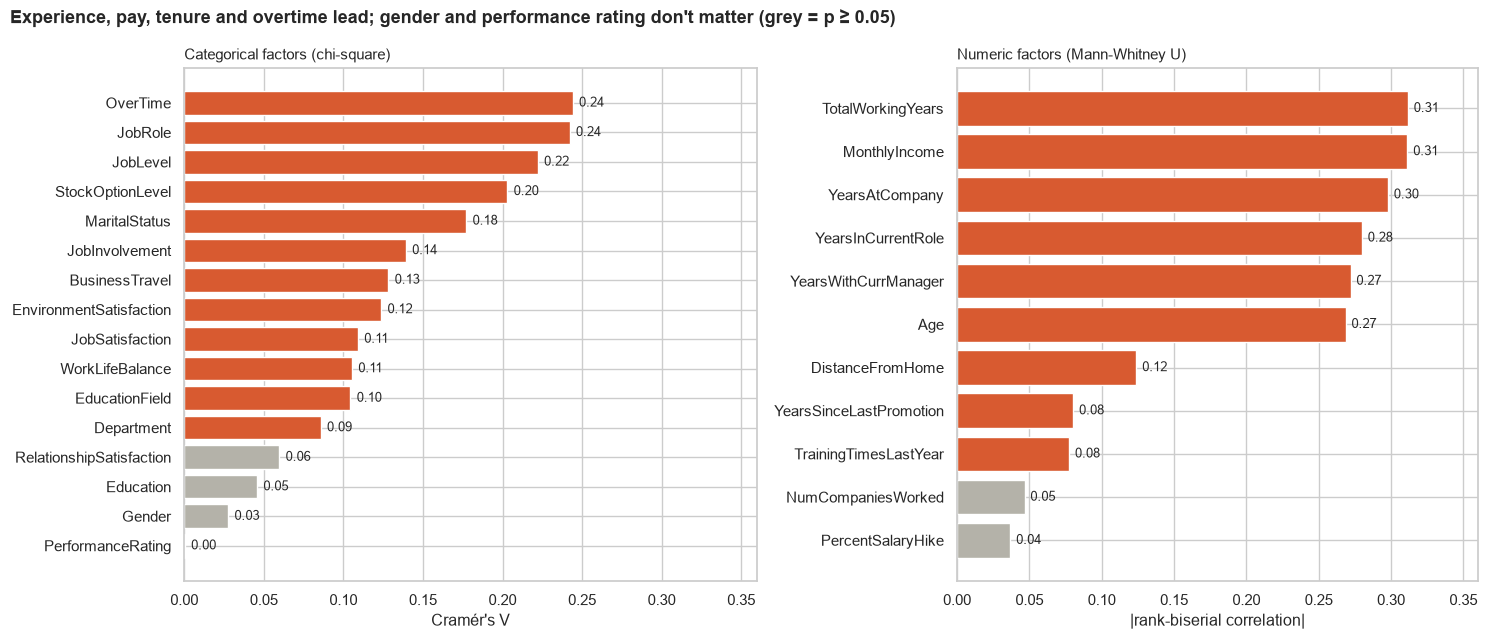

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
for ax, typ, xlabel in [(axes[0], "categorical", "Cramér's V"), (axes[1], "numeric", "|rank-biserial correlation|")]:
    d = drivers[drivers["type"] == typ].sort_values("strength")
    ax.barh(d["factor"], d["strength"], color=[LEFT if s else STAYED for s in d["significant"]])
    for y, v in enumerate(d["strength"]):
        ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=9)
    ax.set_xlabel(xlabel); ax.set_xlim(0, 0.36)
    ax.set_title("Categorical factors (chi-square)" if typ == "categorical" else "Numeric factors (Mann-Whitney U)", loc="left", fontsize=11)
fig.suptitle("Experience, pay, tenure and overtime lead; gender and performance rating don't matter (grey = p ≥ 0.05)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "05_driver_ranking.png", dpi=120, bbox_inches="tight"); plt.show()

**Why two panels:** Cramér's V and rank-biserial correlation are different measures, so each type is ranked on its own scale. The overall picture is the same in both: **experience, pay, tenure, overtime and role** dominate; gender, education and performance rating don't matter.

## 9. Combinations: where the risk really concentrates
Single factors hide the biggest story. Overtime matters much more for some employees than others.

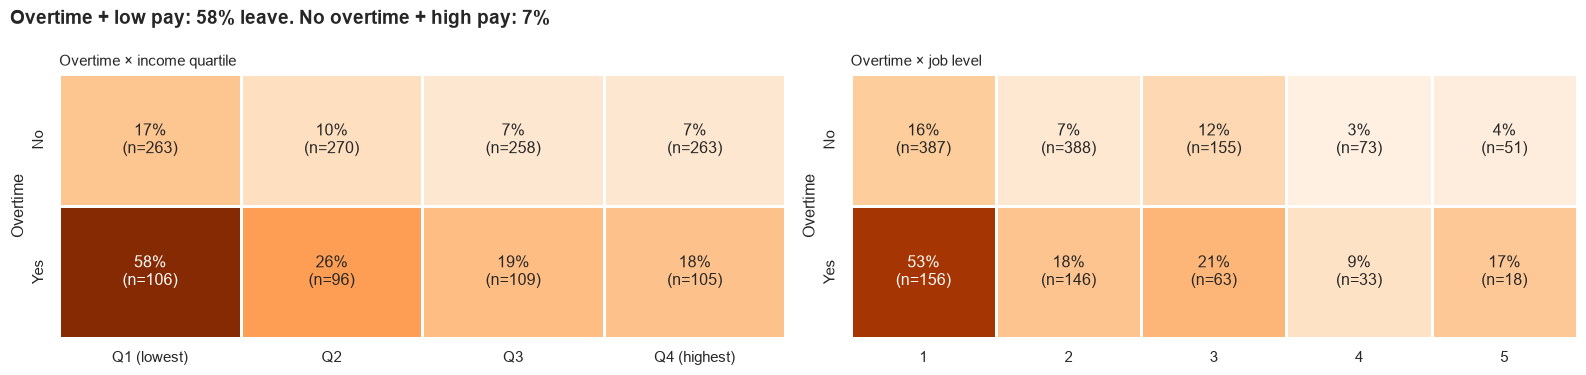

In [15]:
def rate_grid(row, col):
    rate = pd.crosstab(df[row], df[col], values=df["Left"], aggfunc="mean")
    n = pd.crosstab(df[row], df[col])
    return rate, n

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, col, title in [(axes[0], "IncomeQuartile", "Overtime × income quartile"), (axes[1], "JobLevel", "Overtime × job level")]:
    rate, n = rate_grid("OverTime", col)
    annot = rate.map(lambda v: f"{v:.0%}") + "\n(n=" + n.astype(str) + ")"
    sns.heatmap(rate, annot=annot, fmt="", cmap="Oranges", vmin=0, vmax=0.6, cbar=False, ax=ax, linewidths=1)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel(""); ax.set_ylabel("Overtime")
fig.suptitle("Overtime + low pay: 58% leave. No overtime + high pay: 7%", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "06_risk_combinations.png", dpi=120, bbox_inches="tight"); plt.show()

In [16]:
profiles = {
    "Everyone": pd.Series(True, index=df.index),
    "Overtime": df["OverTime"] == "Yes",
    "Overtime + Job Level 1": (df["OverTime"] == "Yes") & (df["JobLevel"] == 1),
    "Overtime + Job Level 1 + Single": (df["OverTime"] == "Yes") & (df["JobLevel"] == 1) & (df["MaritalStatus"] == "Single"),
    "No overtime + Job Level 2+": (df["OverTime"] == "No") & (df["JobLevel"] >= 2),
}
rows = []
for name, mask in profiles.items():
    k, n = df.loc[mask, "Left"].sum(), mask.sum()
    lo, hi = wilson_ci(k, n)
    rows.append({"profile": name, "employees": n, "leavers": k, "rate": k / n, "ci_low": lo, "ci_high": hi})
pd.DataFrame(rows)

,profile,employees,leavers,rate,ci_low,ci_high
0,Everyone,1470,237,0.161,0.143,0.181
1,Overtime,416,127,0.305,0.263,0.351
2,Overtime + Job Level 1,156,82,0.526,0.448,0.602
3,Overtime + Job Level 1 + Single,59,40,0.678,0.551,0.783
4,No overtime + Job Level 2+,667,49,0.073,0.056,0.096


Two out of three single, entry-level employees doing overtime left (68%, 59 people). Employees above entry level without overtime leave at well under 10%. **The risk is concentrated, so retention budgets can be targeted.**

## 10. What doesn't matter (just as useful to report)

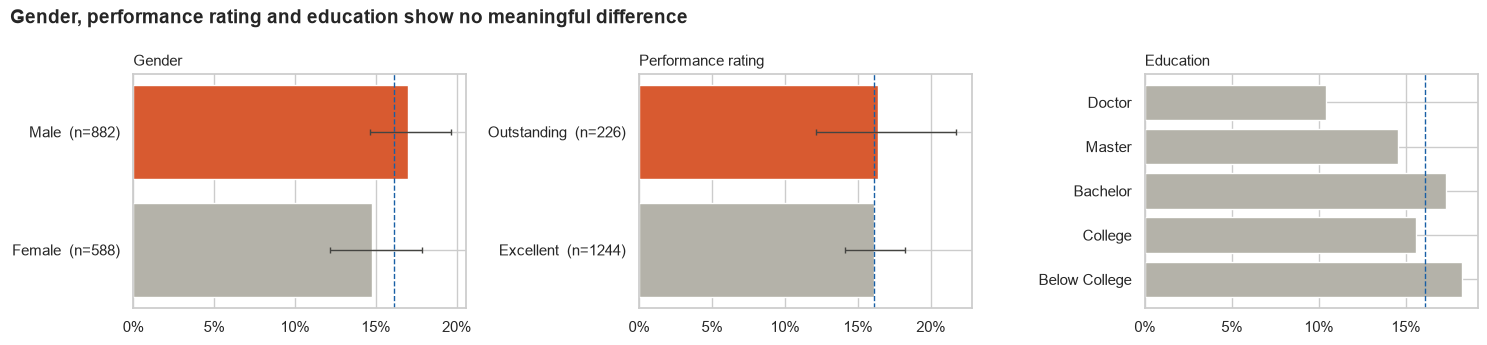

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
plot_rate("Gender", axes[0], "Gender")
plot_rate("PerformanceRating", axes[1], "Performance rating")
t = rate_table("Education").reindex(["Below College", "College", "Bachelor", "Master", "Doctor"])
axes[2].barh(t.index, t["rate"], color=STAYED); axes[2].axvline(OVERALL, ls="--", color=ACCENT, lw=1)
axes[2].set_title("Education", loc="left", fontsize=11)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Gender, performance rating and education show no meaningful difference", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "07_what_doesnt_matter.png", dpi=120, bbox_inches="tight"); plt.show()

**Performance rating** has only two values here (Excellent / Outstanding), so it can't separate weak from strong performers. That's a limitation of the data, not proof that performance is irrelevant.

## 11. Export for the Tableau dashboard

In [18]:
export_cols = ["Attrition", "Left", "Age", "AgeBand", "Gender", "MaritalStatus", "Department", "JobRole", "JobLevel",
               "OverTime", "BusinessTravel", "MonthlyIncome", "IncomeQuartile", "YearsAtCompany", "TenureBand",
               "TotalWorkingYears", "YearsSinceLastPromotion", "StockOptionLevel", "DistanceFromHome",
               "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance", "JobInvolvement", "Education", "EducationField"]
df[export_cols].to_csv("../tableau/hr_attrition_tableau.csv", index=False)
print("Saved", len(df), "rows")

Saved 1470 rows


## 12. Summary

| # | Finding | Evidence | Recommendation |
|---|---|---|---|
| 1 | Overtime is the strongest single driver | 30.5% vs 10.4%; strongest Cramér's V (0.24) | Monitor overtime hours; cap or compensate sustained overtime |
| 2 | Overtime hurts most when pay is low | 58% of low-pay overtime workers left vs 18% of high-pay | Prioritise pay review for low-paid staff on overtime |
| 3 | The first two years are critical | 43% of leavers left within 2 years; 36% rate in year one | Stronger onboarding, 90-day and 1-year check-ins |
| 4 | Sales Reps and Lab Technicians are hotspots | 39.8% and 23.9% vs 16.1% average | Role-specific retention plans, career paths into Sales Executive |
| 5 | Gender, education and performance rating don't predict leaving | p > 0.05, effect ≈ 0 | Don't build retention policy around them |

**Limitation:** fictional data; correlation, not causation (e.g. overtime may be a symptom of under-staffing that also drives attrition).